**Live Deployment Link:** [https://mubashir-ml-assignment-two.mellowllama2.chatgpt.site/?task=heart](https://mubashir-ml-assignment-two.mellowllama2.chatgpt.site/?task=heart)

The demo is currently owner-private. For an instructor-accessible public Python deployment, use the included Streamlit app and replace this link after deploying.

---
# Heart Disease Prediction System

**Mubashir Ali**  
**Registration No.: Fa24-bse-140**  
**Assignment 2 - AIC354 - Fall 2026**


## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (Yes) or not (No) from four clinical attributes.
##### **Application** Educational classification using a four-attribute clinical dataset.

## Input and Output

### Inputs (4 attributes selected from the UCI Heart Disease dataset, Cleveland data)

| **Input Attribute** | **Original UCI Name** | **Possible Values** |
| --- | --- | --- |
| **Sex** | sex | Male, Female |
| **ChestPain** | cp | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **RestECG** | restecg | Normal, ST-T Abnormality, LV Hypertrophy |
| **ExerciseAngina** | exang | Yes, No |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **HeartDisease** | Yes, No |

The original UCI target `num` has values 0 to 4. As is standard for this dataset, 0 means *No* (absence) and 1-4 mean *Yes* (presence).

## Developer & System Information

| Field | Details |
|---|---|
| Student Name | Mubashir Ali |
| Registration No. | Fa24-bse-140 |
| Course | AIC354 Machine Learning Fundamentals |
| Institution | COMSATS University Islamabad, Lahore Campus |
| Instructor | Dr. Rao Muhammad Adeel Nawab |
| Semester | Fall 2026 |
| Program Name | heart_disease_project |
| IDE | Jupyter Notebook |
| Programming Language | Python 3.12 |
| Libraries | NumPy, Pandas, Pickle, scikit-learn, PrettyTable, Matplotlib, Seaborn |


## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data
- Step 6: Execute the Training Phase
- Step 7: Execute the Testing Phase
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deploy the Model as a Public Web App


### Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

`sample-data.csv` is reproduced from the included UCI Cleveland file in Step 2.1. Only `sex`, `cp`, `restecg` and `exang` are selected; `num` is converted to No for 0 and Yes for 1-4.

#### Step 2.1: (Optional) Re-create sample-data.csv from the raw UCI file

In [2]:
import os
if os.path.exists('processed.cleveland.data'):
    cols = 'age sex cp trestbps chol fbs restecg thalach exang oldpeak slope ca thal num'.split()
    raw = pd.read_csv('processed.cleveland.data', header=None, names=cols, na_values='?')
    pd.DataFrame({'Sex': raw.sex.map({1: 'Male', 0: 'Female'}), 'ChestPain': raw.cp.map({1: 'Typical Angina', 2: 'Atypical Angina', 3: 'Non-Anginal Pain', 4: 'Asymptomatic'}), 'RestECG': raw.restecg.map({0: 'Normal', 1: 'ST-T Abnormality', 2: 'LV Hypertrophy'}), 'ExerciseAngina': raw.exang.map({1: 'Yes', 0: 'No'}), 'HeartDisease': (raw.num > 0).map({True: 'Yes', False: 'No'})}).to_csv('sample-data.csv', index=False)
    print('sample-data.csv re-created from processed.cleveland.data')
else:
    print('processed.cleveland.data not found, using the existing sample-data.csv')

sample-data.csv re-created from processed.cleveland.data


#### Step 2.2: Load the data

In [3]:
sample_data = pd.read_csv('sample-data.csv')
print('\n\nSample Data (first 15 rows):')
print('============================\n')
print(sample_data.head(15))



Sample Data (first 15 rows):

       Sex         ChestPain         RestECG ExerciseAngina HeartDisease
0     Male    Typical Angina  LV Hypertrophy             No           No
1     Male      Asymptomatic  LV Hypertrophy            Yes          Yes
2     Male      Asymptomatic  LV Hypertrophy            Yes          Yes
3     Male  Non-Anginal Pain          Normal             No           No
4   Female   Atypical Angina  LV Hypertrophy             No           No
5     Male   Atypical Angina          Normal             No           No
6   Female      Asymptomatic  LV Hypertrophy             No          Yes
7   Female      Asymptomatic          Normal            Yes           No
8     Male      Asymptomatic  LV Hypertrophy             No          Yes
9     Male      Asymptomatic  LV Hypertrophy            Yes          Yes
10    Male      Asymptomatic          Normal             No           No
11  Female   Atypical Angina  LV Hypertrophy             No           No
12    Male  Non-Ang

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [4]:
print('\n\nAttributes in Sample Data:')
print('==========================\n')
print(sample_data.columns)
print('\n\nNumber of Instances in Sample Data:', sample_data['Sex'].count())
print('========================================\n')
print('Missing values per column:')
print(sample_data.isnull().sum())
print('\nClass distribution of the output:')
print(sample_data['HeartDisease'].value_counts())
for col in ['Sex', 'ChestPain', 'RestECG', 'ExerciseAngina']:
    print(f'\n{col}:')
    print(sample_data[col].value_counts())



Attributes in Sample Data:

Index(['Sex', 'ChestPain', 'RestECG', 'ExerciseAngina', 'HeartDisease'], dtype='object')


Number of Instances in Sample Data: 303

Missing values per column:
Sex               0
ChestPain         0
RestECG           0
ExerciseAngina    0
HeartDisease      0
dtype: int64

Class distribution of the output:
HeartDisease
No     164
Yes    139
Name: count, dtype: int64

Sex:
Sex
Male      206
Female     97
Name: count, dtype: int64

ChestPain:
ChestPain
Asymptomatic        144
Non-Anginal Pain     86
Atypical Angina      50
Typical Angina       23
Name: count, dtype: int64

RestECG:
RestECG
Normal              151
LV Hypertrophy      148
ST-T Abnormality      4
Name: count, dtype: int64

ExerciseAngina:
ExerciseAngina
No     204
Yes     99
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
- The 4 chosen attributes contain **no missing values** (the UCI Cleveland file only has missing values in `ca` and `thal`, which we did not select).
- Text labels were already assigned in Step 2.
- No further preprocessing needs to be performed.

#### Step 4: Feature Extraction
- The 4 features are already extracted (selected from the UCI dataset).
- No Feature Extraction needs to be Performed

### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [5]:
sex = pd.DataFrame({'Sex': ['Male', 'Female']})
chestpain = pd.DataFrame({'ChestPain': ['Typical Angina', 'Atypical Angina', 'Non-Anginal Pain', 'Asymptomatic']})
restecg = pd.DataFrame({'RestECG': ['Normal', 'ST-T Abnormality', 'LV Hypertrophy']})
exerciseangina = pd.DataFrame({'ExerciseAngina': ['Yes', 'No']})
heartdisease = pd.DataFrame({'HeartDisease': ['Yes', 'No']})
sex_label_encoder = LabelEncoder()
chestpain_label_encoder = LabelEncoder()
restecg_label_encoder = LabelEncoder()
exerciseangina_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()
sex_label_encoder.fit(np.ravel(sex))
chestpain_label_encoder.fit(np.ravel(chestpain))
restecg_label_encoder.fit(np.ravel(restecg))
exerciseangina_label_encoder.fit(np.ravel(exerciseangina))
heartdisease_label_encoder.fit(np.ravel(heartdisease))
for name, enc in [('Sex', sex_label_encoder), ('ChestPain', chestpain_label_encoder), ('RestECG', restecg_label_encoder), ('ExerciseAngina', exerciseangina_label_encoder), ('HeartDisease', heartdisease_label_encoder)]:
    print(name, '->', {c: int(i) for i, c in enumerate(enc.classes_)})

Sex -> {'Female': 0, 'Male': 1}
ChestPain -> {'Asymptomatic': 0, 'Atypical Angina': 1, 'Non-Anginal Pain': 2, 'Typical Angina': 3}
RestECG -> {'LV Hypertrophy': 0, 'Normal': 1, 'ST-T Abnormality': 2}
ExerciseAngina -> {'No': 0, 'Yes': 1}
HeartDisease -> {'No': 0, 'Yes': 1}


#### Step 5.2: Label Encode the Output

In [6]:
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()
print('\n\nHeartDisease Attribute After Label Encoding:')
print('============================================\n')
sample_data['encoded_heartdisease'] = heartdisease_label_encoder.transform(sample_data['HeartDisease'])
print(sample_data[['HeartDisease', 'encoded_heartdisease']].head(10))
sample_data_encoded_output[['Sex', 'ChestPain', 'RestECG', 'ExerciseAngina', 'HeartDisease']] = sample_data[['Sex', 'ChestPain', 'RestECG', 'ExerciseAngina', 'encoded_heartdisease']]
sample_data_encoded_output.to_csv('sample-data-encoded-output.csv', index=False, header=True)
print('\nSaved: sample-data-encoded-output.csv')



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_heartdisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [7]:
sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded_output['encoded_sex'] = sex_label_encoder.transform(sample_data_encoded_output['Sex'])
sample_data_encoded_output['encoded_chestpain'] = chestpain_label_encoder.transform(sample_data_encoded_output['ChestPain'])
sample_data_encoded_output['encoded_restecg'] = restecg_label_encoder.transform(sample_data_encoded_output['RestECG'])
sample_data_encoded_output['encoded_exerciseangina'] = exerciseangina_label_encoder.transform(sample_data_encoded_output['ExerciseAngina'])
sample_data_encoded[['Sex', 'ChestPain', 'RestECG', 'ExerciseAngina', 'HeartDisease']] = sample_data_encoded_output[['encoded_sex', 'encoded_chestpain', 'encoded_restecg', 'encoded_exerciseangina', 'HeartDisease']]
sample_data_encoded = sample_data_encoded.astype(int)
print('\n\nSample Data after Label Encoding:')
print('=================================\n')
print(sample_data_encoded.head(15))
sample_data_encoded.to_csv('sample-data-encoded.csv', index=False, header=True)



Sample Data after Label Encoding:

    Sex  ChestPain  RestECG  ExerciseAngina  HeartDisease
0     1          3        0               0             0
1     1          0        0               1             1
2     1          0        0               1             1
3     1          2        1               0             0
4     0          1        0               0             0
5     1          1        1               0             0
6     0          0        0               0             1
7     0          0        1               1             0
8     1          0        0               0             1
9     1          0        0               1             1
10    1          0        1               0             0
11    0          1        0               0             0
12    1          2        0               1             1
13    1          1        1               0             0
14    1          2        1               0             0


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data
80% training / 20% testing. Unlike the Titanic notebook (`shuffle=False`), this split **shuffles** the rows and **stratifies** on the output, so both sets keep the same Yes/No proportion. `random_state=0` keeps the split reproducible.

In [8]:
training_data_encoded, testing_data_encoded = train_test_split(sample_data_encoded, test_size=0.2, random_state=0, shuffle=True, stratify=sample_data_encoded['HeartDisease'])
training_data_encoded.to_csv('training-data-encoded.csv', index=False, header=True)
testing_data_encoded.to_csv('testing-data-encoded.csv', index=False, header=True)
print('Training Data shape:', training_data_encoded.shape)
print('Testing Data shape:', testing_data_encoded.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [9]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]
print('Input vectors (train) shape:', input_vector_train.shape)
print('Output labels (train) shape:', output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


### Step 6.3: Train the Support Vector Classifier

In [10]:
print('\n\nTraining the Support Vector Classifier on Training Data')
print('========================================================\n')
svc_model = svm.SVC(gamma='auto', random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [11]:
with open('heart_svc_trained_model.pkl', 'wb') as file:
    pickle.dump(svc_model, file)
print('Saved: heart_svc_trained_model.pkl')

Saved: heart_svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [12]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]
print('Input vectors (test) shape:', input_vector_test.shape)
print('Output labels (test) shape:', output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


### Step 7.2: Load the Saved Model

In [13]:
with open('heart_svc_trained_model.pkl', 'rb') as file:
    model = pickle.load(file)
print('Model loaded from heart_svc_trained_model.pkl')

Model loaded from heart_svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [14]:
model_predictions = model.predict(input_vector_test)
testing_data_encoded = testing_data_encoded.copy()
testing_data_encoded['Predictions'] = model_predictions
testing_data_encoded.to_csv('model-predictions.csv', index=False, header=True)
model_predictions = testing_data_encoded
print('\n\nPredictions Returned by heart_svc_trained_model:')
print('================================================\n')
print(model_predictions.head(15))



Predictions Returned by heart_svc_trained_model:

     Sex  ChestPain  RestECG  ExerciseAngina  HeartDisease  Predictions
125    0          1        0               0             0            0
83     1          2        0               1             1            0
53     1          1        0               0             0            0
45     1          2        0               0             1            0
248    1          0        1               0             1            0
211    1          3        1               1             1            0
36     1          0        0               1             1            1
106    1          0        1               1             1            1
120    1          0        0               1             1            1
31     1          0        1               1             1            1
156    1          0        1               1             1            1
157    1          0        0               0             1            1
148    1    

### Step 7.4: Calculate the Accuracy Score

In [15]:
model_accuracy_score = accuracy_score(model_predictions['HeartDisease'], model_predictions['Predictions'])
print('Accuracy:', round(model_accuracy_score, 4))
print('Accuracy percentage:', round(model_accuracy_score * 100, 2))

Accuracy: 0.8197
Accuracy percentage: 81.97


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.76      0.97      0.85        33
   Heart Disease (1)       0.95      0.64      0.77        28

            accuracy                           0.82        61
           macro avg       0.85      0.81      0.81        61
        weighted avg       0.85      0.82      0.81        61


Confusion Matrix:

             Predicted: No  Predicted: Yes
Actual: No              32               1
Actual: Yes             10              18


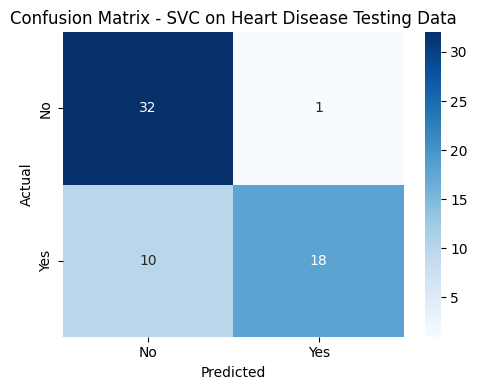

In [16]:
print('\nClassification Report:')
print('=======================\n')
print(classification_report(model_predictions['HeartDisease'], model_predictions['Predictions'], target_names=['No Heart Disease (0)', 'Heart Disease (1)']))
conf_matrix = confusion_matrix(model_predictions['HeartDisease'], model_predictions['Predictions'])
conf_matrix_df = pd.DataFrame(conf_matrix, index=['Actual: No', 'Actual: Yes'], columns=['Predicted: No', 'Predicted: Yes'])
print('\nConfusion Matrix:')
print('==================\n')
print(conf_matrix_df)
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Heart Disease Testing Data')
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

A demo patient is pre-filled so the notebook runs top-to-bottom. To enter your own values interactively, replace the four lines with:
```python
sex_input = input("Sex (Male, Female): ").strip()
chestpain_input = input("ChestPain (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
restecg_input = input("RestECG (Normal, ST-T Abnormality, LV Hypertrophy): ").strip()
exerciseangina_input = input("ExerciseAngina (Yes, No): ").strip()
```

In [17]:
sex_input = 'Male'
chestpain_input = 'Asymptomatic'
restecg_input = 'Normal'
exerciseangina_input = 'Yes'
print(f'Sex: {sex_input}, ChestPain: {chestpain_input}, RestECG: {restecg_input}, ExerciseAngina: {exerciseangina_input}')

Sex: Male, ChestPain: Asymptomatic, RestECG: Normal, ExerciseAngina: Yes


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [18]:
user_input = pd.DataFrame({'Sex': [sex_input], 'ChestPain': [chestpain_input], 'RestECG': [restecg_input], 'ExerciseAngina': [exerciseangina_input]})
print('\n\nUser Input Feature Vector:')
print('==========================\n')
print(user_input)



User Input Feature Vector:

    Sex     ChestPain RestECG ExerciseAngina
0  Male  Asymptomatic  Normal            Yes


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [19]:
unseen_data_features = user_input.copy()
unseen_data_features['Sex'] = sex_label_encoder.transform(user_input['Sex'])
unseen_data_features['ChestPain'] = chestpain_label_encoder.transform(user_input['ChestPain'])
unseen_data_features['RestECG'] = restecg_label_encoder.transform(user_input['RestECG'])
unseen_data_features['ExerciseAngina'] = exerciseangina_label_encoder.transform(user_input['ExerciseAngina'])
print('\n\nUser Input Encoded Feature Vector:')
print('==================================\n')
print(unseen_data_features)



User Input Encoded Feature Vector:

   Sex  ChestPain  RestECG  ExerciseAngina
0    1          0        1               1


### Step 8.4: Load the Saved Model

In [20]:
with open('heart_svc_trained_model.pkl', 'rb') as file:
    model = pickle.load(file)

### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [21]:
predicted_disease = model.predict(unseen_data_features)
if predicted_disease[0] == 1:
    prediction = 'HEART DISEASE LIKELY'
else:
    prediction = 'NO HEART DISEASE LIKELY'
pretty_table = PrettyTable()
pretty_table.add_column('       ** Prediction **       ', [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

The following records are illustrative review examples. No cardiologist or real user feedback is claimed.

In [22]:
example_feedback = pd.DataFrame({
    'Reviewer': ['Illustrative reviewer', 'Illustrative tester', 'Illustrative reviewer'],
    'Case': ['A model predicts the positive class', 'A model predicts the negative class', 'Only four attributes are included'],
    'Feedback': ['Compare the prediction with a verified outcome.', 'Review false negatives using verified labels.', 'Keep the four-input constraint and evaluate alternative four-attribute sets using training data.']
})
print(example_feedback.to_string(index=False))

             Reviewer                                Case                                                                                         Feedback
Illustrative reviewer A model predicts the positive class                                                  Compare the prediction with a verified outcome.
  Illustrative tester A model predicts the negative class                                                    Review false negatives using verified labels.
Illustrative reviewer   Only four attributes are included Keep the four-input constraint and evaluate alternative four-attribute sets using training data.


#### Step 9.2: Make a List of Potential Improvements

In [23]:
improvements = [
    'Use training-only cross-validation to select SVC parameters.',
    'Evaluate alternative sets while retaining exactly four original input attributes.',
    'Collect representative records and verified outcome feedback.',
    'Compare Logistic Regression, Decision Tree and Random Forest under the same four-input constraint.'
]
for i, item in enumerate(improvements, 1):
    print(f'{i}. {item}')

1. Use training-only cross-validation to select SVC parameters.
2. Evaluate alternative sets while retaining exactly four original input attributes.
3. Collect representative records and verified outcome feedback.
4. Compare Logistic Regression, Decision Tree and Random Forest under the same four-input constraint.


#### Step 9.3: Improve the Model Based on Feedback

In [24]:
print('Planned improvement: validate SVC settings using training-only cross-validation and exactly four inputs. Retrain after verified feedback is available; replace the deployed model only after evaluation.')

Planned improvement: validate SVC settings using training-only cross-validation and exactly four inputs. Retrain after verified feedback is available; replace the deployed model only after evaluation.


## Step 10: Deploy the Model as a Public Web App

The cloud demo linked above uses the exact trained SVC parameters. It is currently private. The included `app.py` loads `heart_svc_trained_model.pkl` directly for Streamlit deployment.

1. Upload the contents of `heart_disease_project/` to a public GitHub repository.
2. Sign in at https://share.streamlit.io, choose the repository and branch `main`, and set the main file to `app.py`.
3. Select Python 3.12 and deploy. Keep `requirements.txt` beside `app.py`.
4. Verify predictions in the deployed form, then replace the first notebook cell with the public URL.

Local launch from the project folder:
```bash
python3 -m pip install -r requirements.txt
python3 -m streamlit run app.py
```

The instructor's existing demo is a reference and is not this student's deployment.


## Conclusion
A Support Vector Classifier uses exactly Sex, ChestPain, RestECG and ExerciseAngina from the UCI Cleveland dataset. The model achieved 81.97% accuracy on its 20% held-out test set; Step 7 reports the detailed metrics. The model is an educational classifier; no feature-importance analysis or clinical validation is claimed.

## References
1. Instructor starter: Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab, https://github.com/haqnawaz99/ml-teaching-notebooks.
2. Janosi, Steinbrunn, Pfisterer and Detrano (1989), Heart Disease, UCI Machine Learning Repository: https://doi.org/10.24432/C52P4X. License: CC BY 4.0.
